# CNN Development on a Custom Dataset — Fashion-MNIST Classification

**Course:** CVPR — Mid Assignment (CNN Development on Custom Dataset)
**Student ID:** `<your ID>`
**Notebook:** `CNN_StudentID.ipynb`

**Objective.** Design a custom Convolutional Neural Network (CNN) from scratch in PyTorch and train it to classify
grayscale clothing images from the open-access **Fashion-MNIST** dataset into **10 classes**.
The notebook follows the suggested structure:

1. Import Libraries
2. Load and Explore Dataset
3. Data Preprocessing & Augmentation
4. Define CNN Architecture
5. Training Loop with Validation
6. Evaluate Model on Test Set
7. Visualizations (Loss/Accuracy Curves)
8. Analysis & Discussion of Results
9. Conclusions & Future Work

## 1. Import Libraries

* **PyTorch / torchvision** – tensors, neural-network layers, datasets and image transforms.
* **torchinfo** – prints a detailed, layer-by-layer model summary (output shapes and parameter counts).
* **NumPy, Matplotlib, Seaborn** – numerical work and plots.
* **scikit-learn** – classification report and confusion matrix for test-set evaluation.

A fixed random seed is set so the train/validation split, weight initialisation and data shuffling are reproducible.

In [1]:
import os, time, json, random, copy
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split, Subset
import torchvision
from torchvision import datasets, transforms
from torchinfo import summary
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

# ---- Reproducibility ----
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ---- Device: use a GPU if one is available, otherwise the CPU ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | torchvision {torchvision.__version__} | device: {device}")

PyTorch 2.15.0+cu132 | torchvision 0.29.2+cu132 | device: cpu


## 2. Load and Explore Dataset

### Dataset description
**Fashion-MNIST** (Zalando Research, Xiao et al., 2017) is an open-access image-classification dataset released under the MIT licence.
It is available on [Kaggle](https://www.kaggle.com/datasets/zalando-research/fashionmnist),
[Hugging Face](https://huggingface.co/datasets/zalando-datasets/fashion_mnist) and
[GitHub](https://github.com/zalandoresearch/fashion-mnist), and is built into `torchvision`.

| Property | Value |
|---|---|
| Images | 70,000 (60,000 train + 10,000 test) |
| Image size | 28 × 28 pixels, 1 channel (grayscale), pixel values 0–255 |
| Classes | 10, perfectly balanced (6,000 train + 1,000 test per class) |
| Content | Product photos of clothing items from Zalando's catalogue |

Class labels: `0 T-shirt/top, 1 Trouser, 2 Pullover, 3 Dress, 4 Coat, 5 Sandal, 6 Shirt, 7 Sneaker, 8 Bag, 9 Ankle boot`.

It is harder than handwritten-digit MNIST because several classes (shirt, T-shirt, pullover, coat) look very similar,
which makes it a good benchmark for a custom CNN. `download=True` fetches the files on first run and re-uses them afterwards.

In [2]:
DATA_DIR = "./data"
CLASSES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Raw datasets (no transforms) used only for exploration
raw_train = datasets.FashionMNIST(DATA_DIR, train=True,  download=True)
raw_test  = datasets.FashionMNIST(DATA_DIR, train=False, download=True)

print("Training images :", len(raw_train))
print("Test images     :", len(raw_test))
print("Image shape     :", tuple(raw_train.data.shape[1:]), "| dtype:", raw_train.data.dtype)
print("Pixel range     :", raw_train.data.min().item(), "-", raw_train.data.max().item())
print("Number of classes:", len(raw_train.classes))

Training images : 60000
Test images     : 10000
Image shape     : (28, 28) | dtype: torch.uint8
Pixel range     : 0 - 255
Number of classes: 10


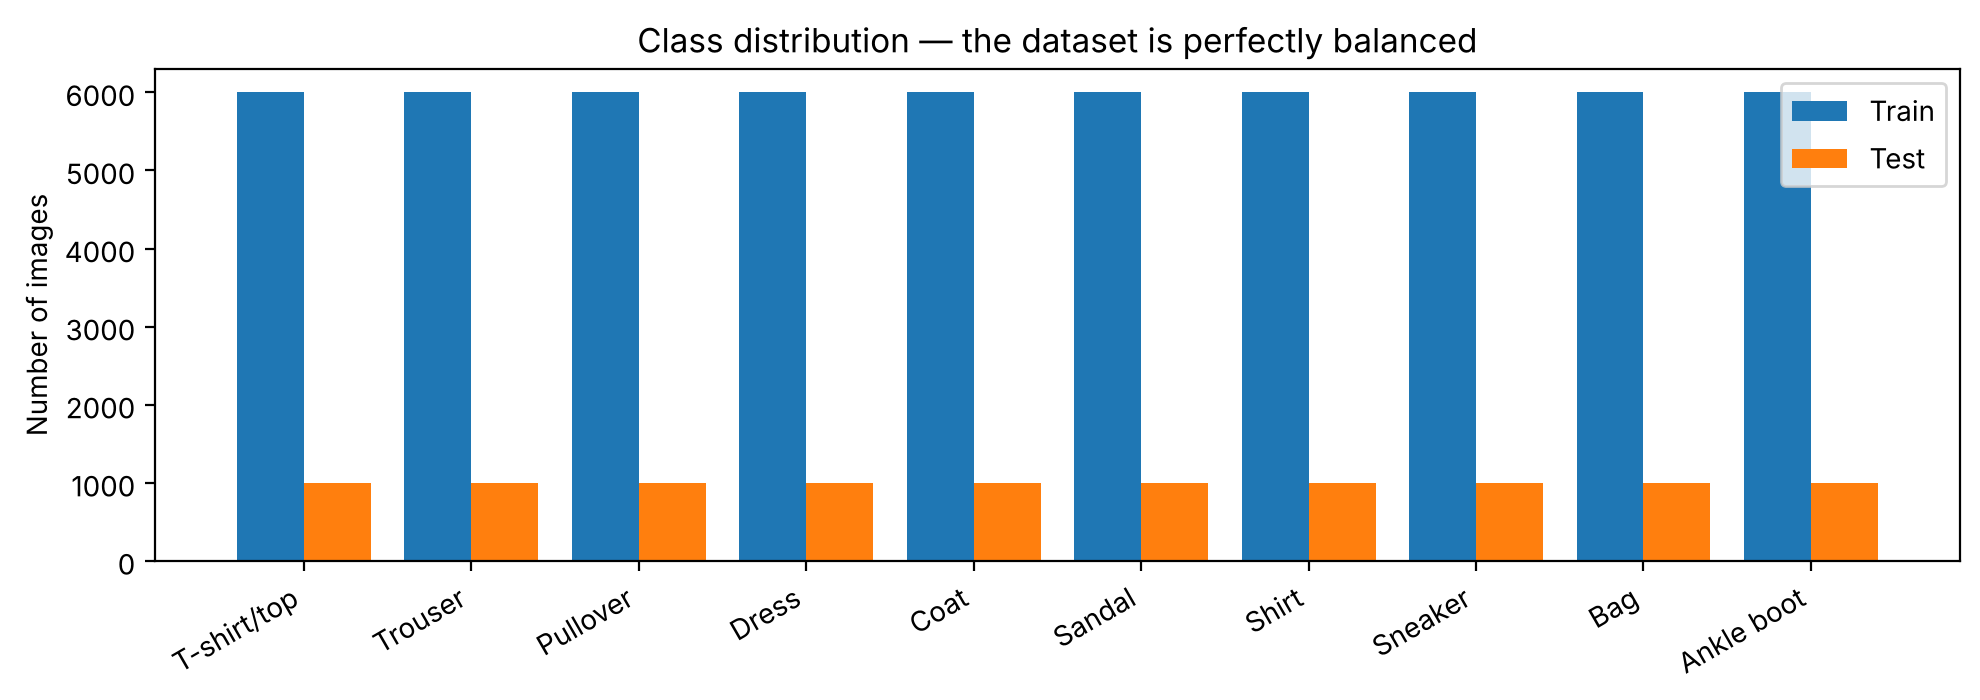

T-shirt/top  train= 6000  test= 1000
Trouser      train= 6000  test= 1000
Pullover     train= 6000  test= 1000
Dress        train= 6000  test= 1000
Coat         train= 6000  test= 1000
Sandal       train= 6000  test= 1000
Shirt        train= 6000  test= 1000
Sneaker      train= 6000  test= 1000
Bag          train= 6000  test= 1000
Ankle boot   train= 6000  test= 1000


In [3]:
# ---- Class distribution (train and test) ----
train_counts = np.bincount(raw_train.targets.numpy(), minlength=10)
test_counts  = np.bincount(raw_test.targets.numpy(),  minlength=10)

fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(10)
ax.bar(x - 0.2, train_counts, width=0.4, label="Train")
ax.bar(x + 0.2, test_counts,  width=0.4, label="Test")
ax.set_xticks(x); ax.set_xticklabels(CLASSES, rotation=30, ha="right")
ax.set_ylabel("Number of images"); ax.set_title("Class distribution — the dataset is perfectly balanced")
ax.legend(); plt.tight_layout(); plt.show()
for c, tr, te in zip(CLASSES, train_counts, test_counts):
    print(f"{c:12s} train={tr:5d}  test={te:5d}")

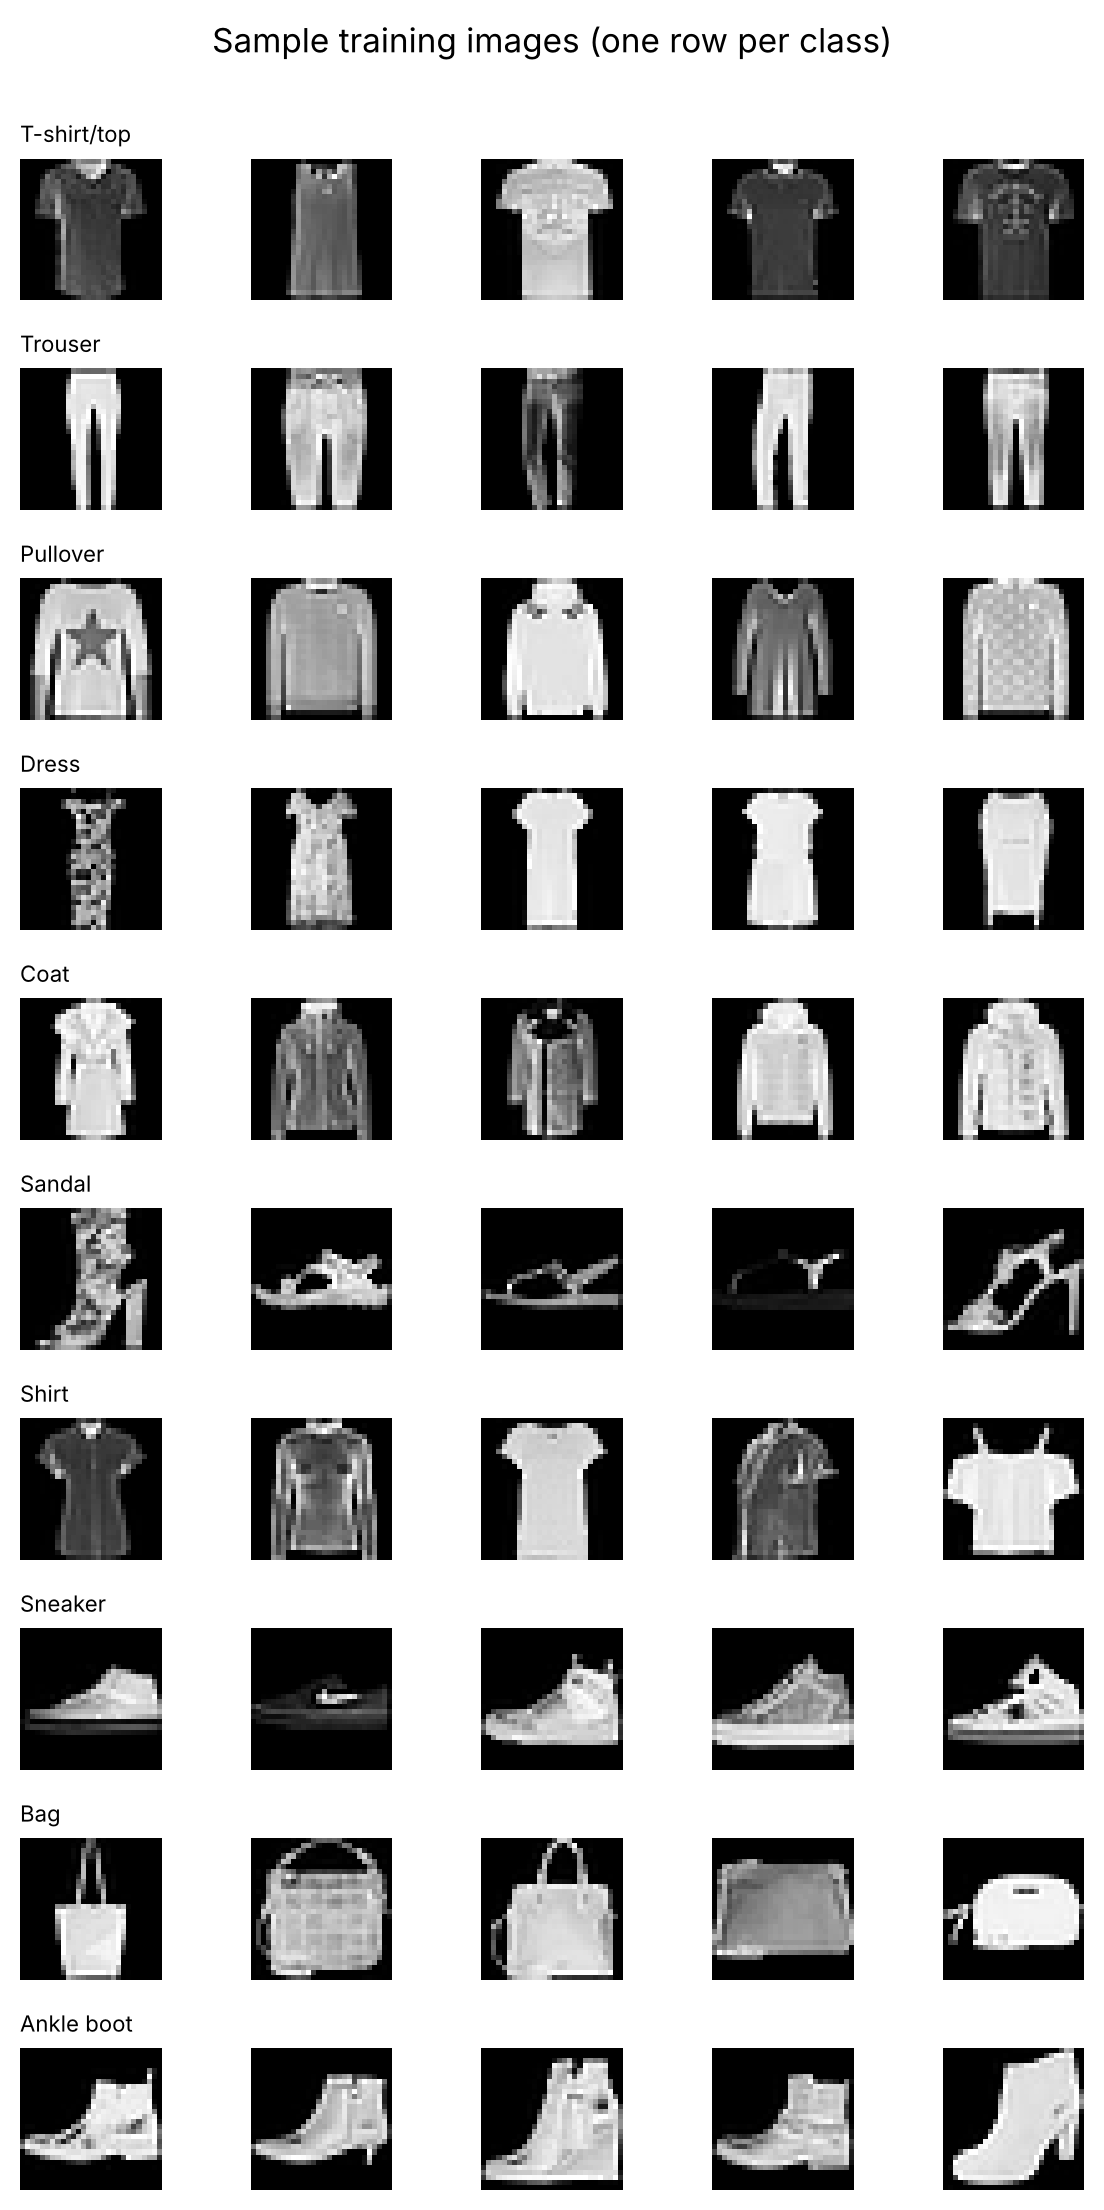

In [4]:
# ---- Visualise 5 random samples from every class ----
fig, axes = plt.subplots(10, 5, figsize=(6, 11))
targets = raw_train.targets.numpy()
for c in range(10):
    idx = np.random.choice(np.where(targets == c)[0], 5, replace=False)
    for j, i in enumerate(idx):
        axes[c, j].imshow(raw_train.data[i], cmap="gray")
        axes[c, j].axis("off")
    axes[c, 0].set_title(CLASSES[c], fontsize=8, loc="left")
plt.suptitle("Sample training images (one row per class)", y=1.0)
plt.tight_layout(); plt.show()

Training-set mean = 0.2860, std = 0.3530


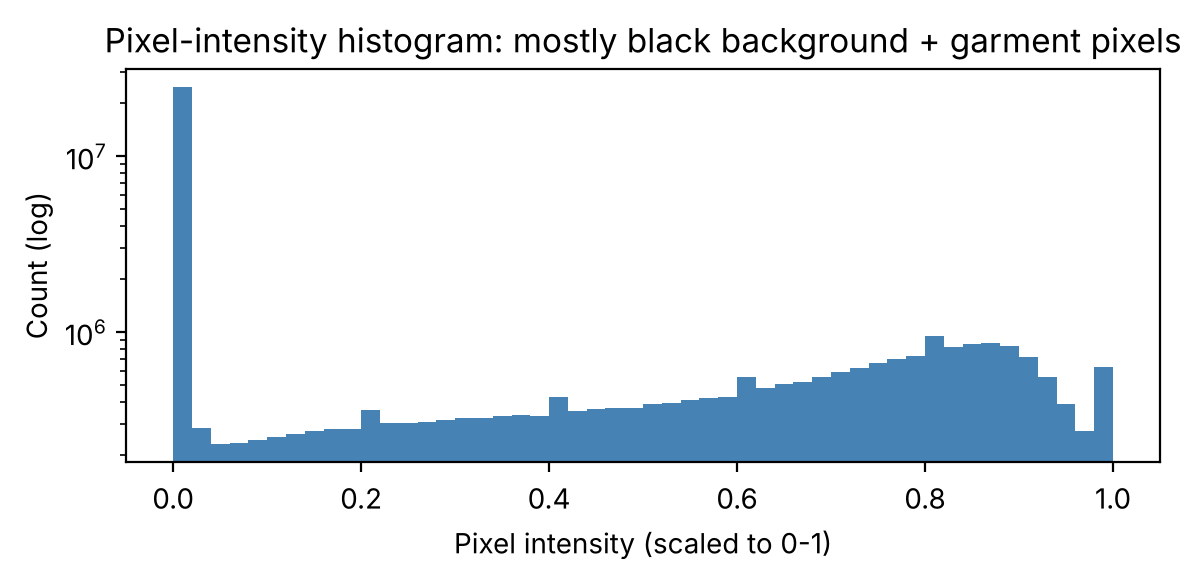

In [5]:
# ---- Pixel statistics, computed on the TRAINING set only (used for normalisation) ----
pixels = raw_train.data.float() / 255.0
MEAN, STD = pixels.mean().item(), pixels.std().item()
print(f"Training-set mean = {MEAN:.4f}, std = {STD:.4f}")

plt.figure(figsize=(6, 3))
plt.hist(pixels.flatten().numpy(), bins=50, color="steelblue")
plt.yscale("log"); plt.xlabel("Pixel intensity (scaled to 0-1)"); plt.ylabel("Count (log)")
plt.title("Pixel-intensity histogram: mostly black background + garment pixels")
plt.tight_layout(); plt.show()

## 3. Data Preprocessing & Augmentation

**Preprocessing (all splits)**
* `ToTensor()` – converts the 28×28 uint8 image to a float tensor in [0, 1] with shape (1, 28, 28).
* `Normalize(mean, std)` – standardises pixels with the **training-set** mean and std so inputs are centred around 0, which
  speeds up and stabilises gradient-based training. Using only training statistics avoids information leaking from the test set.

**Augmentation (training split only)**
* `RandomHorizontalFlip(p=0.5)` – clothing is left/right symmetric, so a mirrored image is still a valid example of the same class.
* `RandomCrop(28, padding=2)` – random shifts of up to 2 pixels make the model tolerant to small changes in position.

Vertical flips and large rotations are **not** used because they create unrealistic images (e.g. an upside-down shoe).
Validation and test images are never augmented, so they measure performance on real, unmodified data.

**Splits.** The official 60,000-image training set is split **90 % / 10 %** into training (54,000) and validation (6,000) sets with a fixed seed.
The validation set is used to monitor over-fitting and to choose the best epoch. The official 10,000-image test set is used **once**, at the end.

In [6]:
# ---- Transforms ----
train_tf = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(28, padding=2),
    transforms.ToTensor(),
    transforms.Normalize((MEAN,), (STD,)),
])
eval_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((MEAN,), (STD,)),
])

# Two views of the same 60k training images: one augmented (for training) and one clean (for validation)
full_train_aug   = datasets.FashionMNIST(DATA_DIR, train=True,  download=True, transform=train_tf)
full_train_clean = datasets.FashionMNIST(DATA_DIR, train=True,  download=True, transform=eval_tf)
test_set         = datasets.FashionMNIST(DATA_DIR, train=False, download=True, transform=eval_tf)

# ---- 90/10 train/validation split with a fixed generator (reproducible) ----
VAL_FRACTION = 0.10
n_val   = int(len(full_train_aug) * VAL_FRACTION)
n_train = len(full_train_aug) - n_val
perm = torch.randperm(len(full_train_aug), generator=torch.Generator().manual_seed(SEED))
train_idx, val_idx = perm[:n_train].tolist(), perm[n_train:].tolist()

train_set = Subset(full_train_aug,   train_idx)   # augmented
val_set   = Subset(full_train_clean, val_idx)     # not augmented

print(f"Train: {len(train_set)} | Validation: {len(val_set)} | Test: {len(test_set)}")

Train: 54000 | Validation: 6000 | Test: 10000


In [7]:
# ---- DataLoaders ----
BATCH_SIZE  = 128
NUM_WORKERS = 2 if device.type == "cuda" else 0

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, generator=torch.Generator().manual_seed(SEED))
val_loader   = DataLoader(val_set,   batch_size=256, shuffle=False, num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_set,  batch_size=256, shuffle=False, num_workers=NUM_WORKERS)

print(f"Batches per epoch -> train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")

# Sanity check: one batch
xb, yb = next(iter(train_loader))
print("One training batch:", tuple(xb.shape), tuple(yb.shape),
      f"| normalised range [{xb.min():.2f}, {xb.max():.2f}]")

Batches per epoch -> train: 422, val: 24, test: 40
One training batch: (128, 1, 28, 28) (128,) | normalised range [-0.81, 2.02]


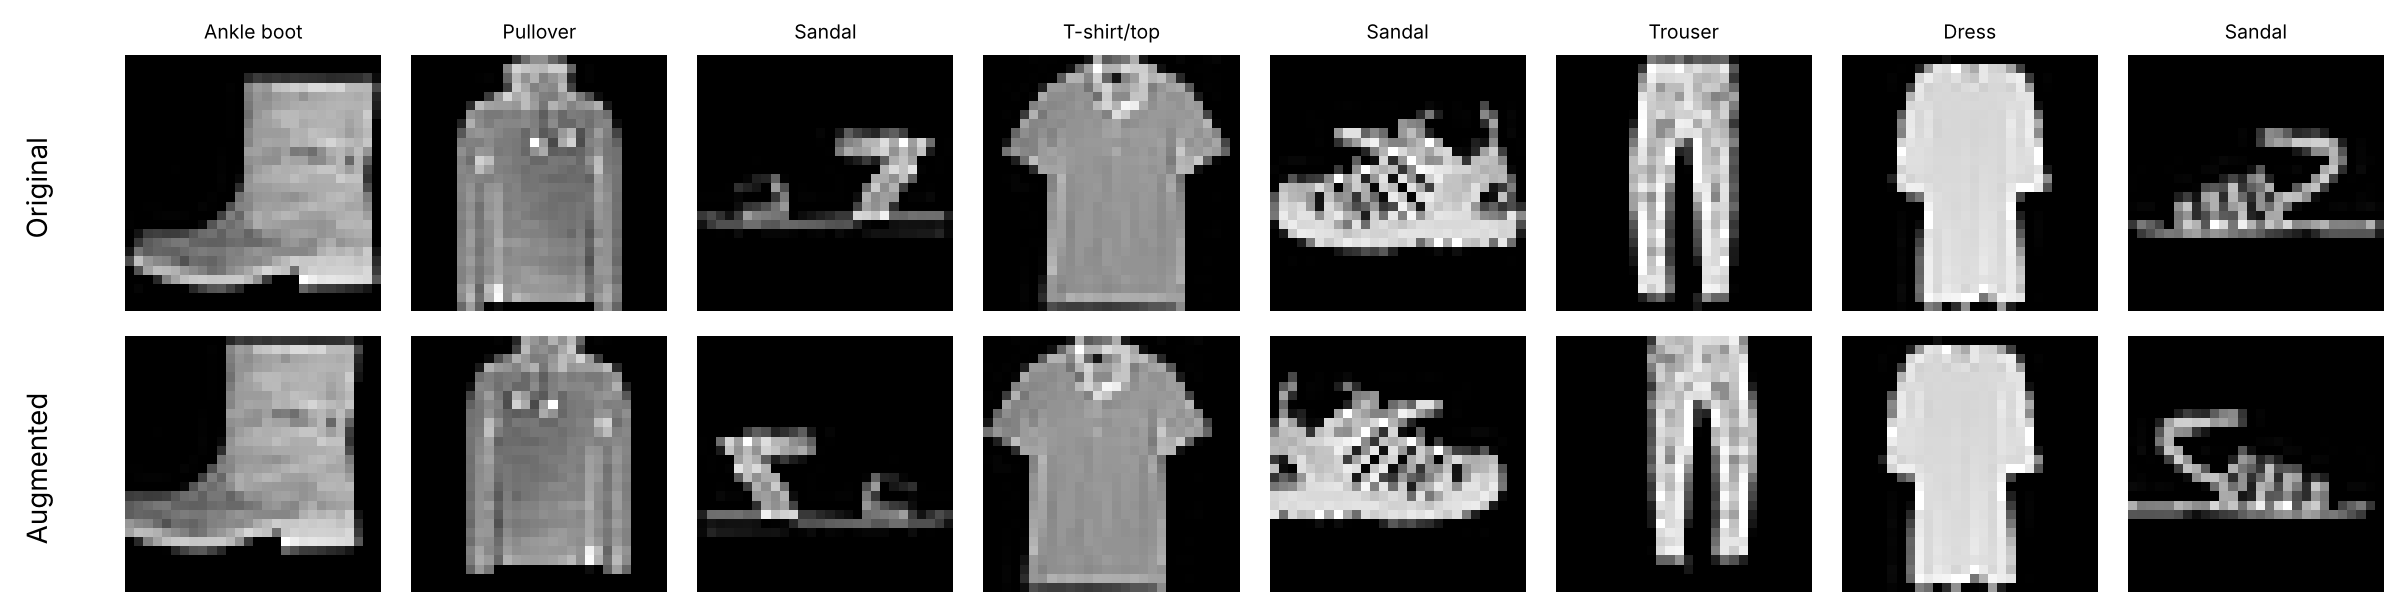

In [8]:
# ---- Show the effect of augmentation on a few training images ----
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for j in range(8):
    i = train_idx[j]
    axes[0, j].imshow(raw_train.data[i], cmap="gray"); axes[0, j].set_title(CLASSES[raw_train.targets[i]], fontsize=7)
    aug_img, _ = full_train_aug[i]
    axes[1, j].imshow(aug_img.squeeze() * STD + MEAN, cmap="gray")
    axes[0, j].axis("off"); axes[1, j].axis("off")
axes[0, 0].text(-12, 14, "Original", rotation=90, va="center")
axes[1, 0].text(-12, 14, "Augmented", rotation=90, va="center")
plt.tight_layout(); plt.show()

## 4. Define CNN Architecture

The custom CNN (`FashionCNN`) follows a VGG-style design: small 3×3 convolutions stacked in blocks, each block followed by max-pooling,
then a small fully connected classifier.

| Stage | Layers | Output shape |
|---|---|---|
| Input | grayscale image | 1 × 28 × 28 |
| Block 1 | [Conv 3×3 (32) → BatchNorm → ReLU] × 2 → MaxPool 2×2 → Dropout 0.25 | 32 × 14 × 14 |
| Block 2 | [Conv 3×3 (64) → BatchNorm → ReLU] × 2 → MaxPool 2×2 → Dropout 0.25 | 64 × 7 × 7 |
| Block 3 | Conv 3×3 (128) → BatchNorm → ReLU → MaxPool 2×2 → Dropout 0.25 | 128 × 3 × 3 |
| Classifier | Flatten → Linear 1152→256 → ReLU → Dropout 0.5 → Linear 256→10 | 10 class scores (logits) |

**Design justification**
* **3×3 kernels with `padding=1`** keep the spatial size inside a block. Two stacked 3×3 convolutions see a 5×5 region with fewer
  parameters and an extra non-linearity compared with one 5×5 kernel.
* **Channels double (32 → 64 → 128) as resolution halves (28 → 14 → 7 → 3)**: early layers learn edges and textures, deeper layers learn
  garment parts (collars, sleeves, soles) that need more feature maps.
* **Batch Normalisation** after each convolution stabilises activations, allows a higher learning rate and speeds up convergence.
  Because BatchNorm has its own shift term, the convolutions use `bias=False`.
* **ReLU** is the standard, cheap non-linearity that avoids vanishing gradients.
* **Max-pooling** halves resolution, adds small translation invariance and reduces computation.
* **Dropout** (0.25 after conv blocks, 0.5 in the classifier) reduces over-fitting by randomly turning off units during training.
* **No softmax in `forward`**: `nn.CrossEntropyLoss` applies log-softmax internally, which is numerically more stable.
* With about **0.44 M parameters (≈1.7 MB)** the model is large enough for 28×28 images, trains in minutes on a CPU, and the saved weights are far
  below the 20 MB GitHub limit.

In [9]:
class FashionCNN(nn.Module):
    # Custom CNN for 28x28 grayscale images, 10 output classes.

    def __init__(self, num_classes: int = 10, p_conv: float = 0.25, p_fc: float = 0.5):
        super().__init__()

        def conv_bn_relu(in_ch, out_ch):
            # 3x3 convolution (size-preserving) + BatchNorm + ReLU
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
            )

        # Feature extractor
        self.block1 = nn.Sequential(conv_bn_relu(1, 32),  conv_bn_relu(32, 32),
                                    nn.MaxPool2d(2), nn.Dropout(p_conv))      # -> 32 x 14 x 14
        self.block2 = nn.Sequential(conv_bn_relu(32, 64), conv_bn_relu(64, 64),
                                    nn.MaxPool2d(2), nn.Dropout(p_conv))      # -> 64 x 7 x 7
        self.block3 = nn.Sequential(conv_bn_relu(64, 128),
                                    nn.MaxPool2d(2), nn.Dropout(p_conv))      # -> 128 x 3 x 3

        # Classifier head
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 3 * 3, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p_fc),
            nn.Linear(256, num_classes),   # raw logits (CrossEntropyLoss applies softmax)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        return self.classifier(x)


model = FashionCNN(num_classes=len(CLASSES)).to(device)
print(model)

FashionCNN(
  (block1): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Sequential(
      (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Dropout(p=0.25, inplace=False)
  )
  (block2): Sequential(
    (0): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Sequential(
      (0): Conv2d(64, 64, kernel_size=(3, 3), st

### Detailed model summary
`torchinfo.summary` lists every layer with its output shape and number of trainable parameters for a batch of 128 images.

In [10]:
summary(model, input_size=(BATCH_SIZE, 1, 28, 28),
        col_names=("input_size", "output_size", "num_params", "kernel_size"),
        depth=3, device=device)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Kernel Shape
FashionCNN                               [128, 1, 28, 28]          [128, 10]                 --                        --
├─Sequential: 1-1                        [128, 1, 28, 28]          [128, 32, 14, 14]         --                        --
│    └─Sequential: 2-1                   [128, 1, 28, 28]          [128, 32, 28, 28]         --                        --
│    │    └─Conv2d: 3-1                  [128, 1, 28, 28]          [128, 32, 28, 28]         288                       [3, 3]
│    │    └─BatchNorm2d: 3-2             [128, 32, 28, 28]         [128, 32, 28, 28]         64                        --
│    │    └─ReLU: 3-3                    [128, 32, 28, 28]         [128, 32, 28, 28]         --                        --
│    └─Sequential: 2-2                   [128, 32, 28, 28]         [128, 32, 28, 28]         --                        --
│    │    

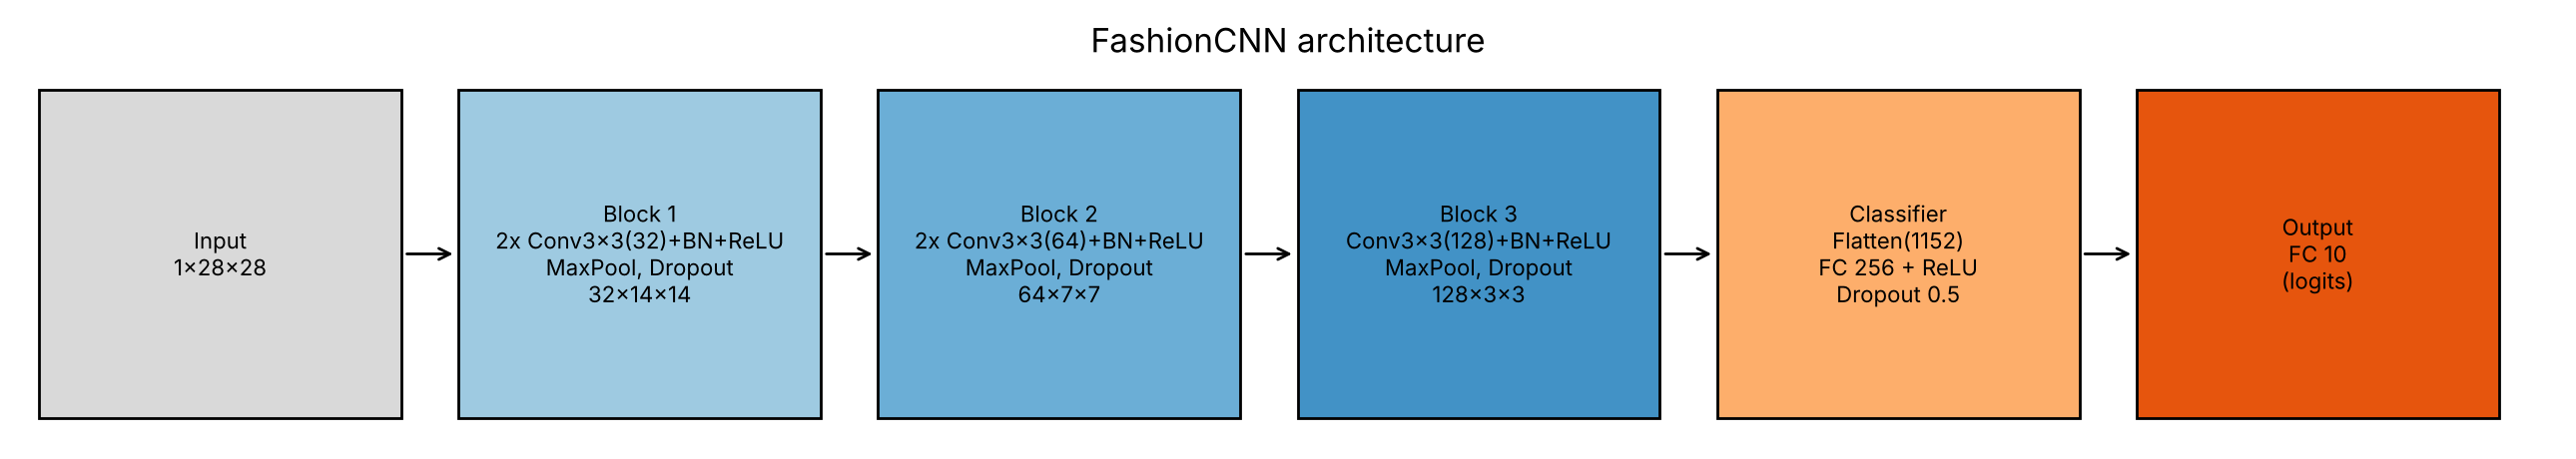

In [11]:
# ---- Simple block diagram of the architecture ----
stages = [("Input\n1x28x28", "#d9d9d9"), ("Block 1\n2x Conv3x3(32)+BN+ReLU\nMaxPool, Dropout\n32x14x14", "#9ecae1"),
          ("Block 2\n2x Conv3x3(64)+BN+ReLU\nMaxPool, Dropout\n64x7x7", "#6baed6"),
          ("Block 3\nConv3x3(128)+BN+ReLU\nMaxPool, Dropout\n128x3x3", "#4292c6"),
          ("Classifier\nFlatten(1152)\nFC 256 + ReLU\nDropout 0.5", "#fdae6b"), ("Output\nFC 10\n(logits)", "#e6550d")]
fig, ax = plt.subplots(figsize=(13, 2.4))
for i, (txt, col) in enumerate(stages):
    ax.add_patch(plt.Rectangle((i * 2.2, 0), 1.9, 1.6, fc=col, ec="k"))
    ax.text(i * 2.2 + 0.95, 0.8, txt, ha="center", va="center", fontsize=8)
    if i < len(stages) - 1:
        ax.annotate("", xy=(i * 2.2 + 2.2, 0.8), xytext=(i * 2.2 + 1.9, 0.8), arrowprops=dict(arrowstyle="->"))
ax.set_xlim(-0.1, len(stages) * 2.2); ax.set_ylim(-0.1, 1.7); ax.axis("off")
ax.set_title("FashionCNN architecture"); plt.tight_layout(); plt.show()

## 5. Training Loop with Validation

### Hyperparameters and rationale

| Hyperparameter | Value | Rationale |
|---|---|---|
| Loss function | Cross-entropy (`nn.CrossEntropyLoss`) | Standard loss for single-label multi-class classification; it combines log-softmax and negative log-likelihood. |
| Optimizer | **Adam** | Adaptive per-parameter learning rates give fast, reliable convergence with little tuning; it works well with BatchNorm. |
| Initial learning rate | 1 × 10⁻³ | Adam's widely used default; stable with BatchNorm. |
| Weight decay (L2) | 1 × 10⁻⁴ | Light regularisation that discourages very large weights. |
| LR schedule | Cosine annealing, 15 epochs → 1 × 10⁻⁵ | Large steps early for fast progress, small steps late to fine-tune; no manual step points needed. |
| Batch size | 128 | Good balance of gradient stability, speed and memory on CPU/GPU; 422 updates per epoch. |
| Epochs | 15 | Validation accuracy levels off by about epoch 12–15 for this model size, so more epochs cost time without benefit. |
| Dropout | 0.25 (conv) / 0.5 (FC) | Standard values; strongest in the fully connected layer, which holds most of the parameters. |
| Model selection | Best validation accuracy | The weights from the epoch with the highest validation accuracy are kept and saved (a form of early stopping). |

Each epoch: (1) **train** – forward pass, loss, back-propagation, Adam step, using dropout and augmentation;
(2) **validate** – `model.eval()` and `torch.no_grad()`, no augmentation, no dropout; (3) step the learning-rate scheduler and log the metrics.

In [12]:
# ---- Hyperparameters ----
EPOCHS        = 15
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 1e-4

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-5)


def train_one_epoch(model, loader, criterion, optimizer):
    # One pass over the training data. Returns (mean loss, accuracy).
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()                 # 1. clear old gradients
        outputs = model(images)               # 2. forward pass
        loss = criterion(outputs, labels)     # 3. cross-entropy loss
        loss.backward()                       # 4. back-propagation
        optimizer.step()                      # 5. update weights
        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    # Evaluate without gradient tracking. Returns (mean loss, accuracy, all predictions, all labels).
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        running_loss += criterion(outputs, labels).item() * images.size(0)
        preds = outputs.argmax(1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        all_preds.append(preds.cpu()); all_labels.append(labels.cpu())
    return running_loss / total, correct / total, torch.cat(all_preds).numpy(), torch.cat(all_labels).numpy()

In [13]:
# ---- Main training loop ----
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [], "lr": []}
best_val_acc, best_epoch = 0.0, 0
best_state = None
start = time.time()

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
    va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion)
    lr_now = optimizer.param_groups[0]["lr"]
    scheduler.step()

    for k, v in zip(history, (tr_loss, tr_acc, va_loss, va_acc, lr_now)):
        history[k].append(v)

    # keep a copy of the best model (highest validation accuracy)
    flag = ""
    if va_acc > best_val_acc:
        best_val_acc, best_epoch = va_acc, epoch
        best_state = copy.deepcopy(model.state_dict())
        flag = "  <- best"

    print(f"Epoch {epoch:2d}/{EPOCHS} | lr {lr_now:.2e} | "
          f"train loss {tr_loss:.4f} acc {tr_acc*100:5.2f}% | "
          f"val loss {va_loss:.4f} acc {va_acc*100:5.2f}% | {time.time()-t0:4.1f}s{flag}")

print(f"\nTraining finished in {(time.time()-start)/60:.1f} min. "
      f"Best validation accuracy {best_val_acc*100:.2f}% at epoch {best_epoch}.")

Epoch  1/15 | lr 1.00e-03 | train loss 0.6782 acc 74.80% | val loss 0.3920 acc 85.12% | 88.9s  <- best


Epoch  2/15 | lr 9.89e-04 | train loss 0.4347 acc 84.10% | val loss 0.3448 acc 86.83% | 85.0s  <- best


Epoch  3/15 | lr 9.57e-04 | train loss 0.3831 acc 86.13% | val loss 0.2963 acc 89.20% | 79.2s  <- best


Epoch  4/15 | lr 9.05e-04 | train loss 0.3451 acc 87.32% | val loss 0.2828 acc 89.42% | 80.1s  <- best


Epoch  5/15 | lr 8.36e-04 | train loss 0.3255 acc 88.11% | val loss 0.2745 acc 89.88% | 81.0s  <- best


Epoch  6/15 | lr 7.52e-04 | train loss 0.3068 acc 88.85% | val loss 0.2582 acc 90.28% | 79.9s  <- best


... (5 outputs left out)

Epoch 12/15 | lr 1.74e-04 | train loss 0.2404 acc 91.31% | val loss 0.2027 acc 92.42% | 77.9s  <- best


Epoch 13/15 | lr 1.05e-04 | train loss 0.2353 acc 91.54% | val loss 0.1985 acc 92.82% | 77.3s  <- best


Epoch 14/15 | lr 5.28e-05 | train loss 0.2277 acc 91.81% | val loss 0.2004 acc 92.72% | 75.8s


Epoch 15/15 | lr 2.08e-05 | train loss 0.2253 acc 91.85% | val loss 0.1971 acc 92.82% | 82.0s

Training finished in 19.9 min. Best validation accuracy 92.82% at epoch 13.


### Save the trained model weights
The best model's `state_dict` (weights only, the recommended PyTorch format) is saved as a `.pth` file together with the information needed
to rebuild and reuse it (class names, normalisation statistics, hyperparameters). The training history is saved as JSON.

In [14]:
os.makedirs("saved_models", exist_ok=True)
WEIGHTS_PATH = "saved_models/fashion_cnn_best.pth"

model.load_state_dict(best_state)          # restore the best epoch
torch.save({
    "model_state_dict": best_state,
    "classes": CLASSES,
    "mean": MEAN, "std": STD,
    "best_epoch": best_epoch, "best_val_acc": best_val_acc,
    "hyperparameters": {"epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LEARNING_RATE,
                        "weight_decay": WEIGHT_DECAY, "optimizer": "Adam", "scheduler": "CosineAnnealingLR"},
}, WEIGHTS_PATH)
with open("saved_models/history.json", "w") as f:
    json.dump(history, f)

print(f"Saved {WEIGHTS_PATH} ({os.path.getsize(WEIGHTS_PATH)/1e6:.2f} MB)")

Saved saved_models/fashion_cnn_best.pth (1.76 MB)


### Load the saved model (self-study: save → load → verify)
A fresh model is created, the saved weights are loaded into it, and it is checked on the validation set to show that the file reproduces
the trained model.

In [15]:
checkpoint = torch.load(WEIGHTS_PATH, map_location=device)
loaded_model = FashionCNN(num_classes=len(checkpoint["classes"])).to(device)
loaded_model.load_state_dict(checkpoint["model_state_dict"])
loaded_model.eval()

_, val_acc_loaded, _, _ = evaluate(loaded_model, val_loader, criterion)
print(f"Loaded model -> best epoch {checkpoint['best_epoch']}, validation accuracy {val_acc_loaded*100:.2f}% "
      f"(stored: {checkpoint['best_val_acc']*100:.2f}%)")

Loaded model -> best epoch 13, validation accuracy 92.82% (stored: 92.82%)


## 6. Evaluate Model on Test Set

The saved model is evaluated **once** on the 10,000 unseen test images. Reported metrics:
* **Accuracy** – fraction of correctly classified images.
* **Precision / Recall / F1-score per class** – precision: how many images predicted as a class really belong to it;
  recall: how many images of a class were found; F1: their harmonic mean.
* **Macro average** – the unweighted mean over the 10 classes (equal to the weighted mean here because the classes are balanced).
* **Confusion matrix** – which classes are confused with each other.

In [16]:
test_loss, test_acc, test_preds, test_labels = evaluate(loaded_model, test_loader, criterion)
prec, rec, f1, _ = precision_recall_fscore_support(test_labels, test_preds, average="macro")

print(f"Test loss          : {test_loss:.4f}")
print(f"Test accuracy      : {test_acc*100:.2f}%")
print(f"Macro precision    : {prec*100:.2f}%")
print(f"Macro recall       : {rec*100:.2f}%")
print(f"Macro F1-score     : {f1*100:.2f}%\n")
print(classification_report(test_labels, test_preds, target_names=CLASSES, digits=4))

with open("saved_models/test_metrics.json", "w") as f:
    json.dump({"test_loss": test_loss, "test_acc": test_acc, "macro_precision": prec,
               "macro_recall": rec, "macro_f1": f1}, f, indent=2)

Test loss          : 0.2093
Test accuracy      : 92.37%
Macro precision    : 92.37%
Macro recall       : 92.37%
Macro F1-score     : 92.36%

              precision    recall  f1-score   support

 T-shirt/top     0.8851    0.8780    0.8815      1000
     Trouser     0.9919    0.9850    0.9885      1000
    Pullover     0.8953    0.8980    0.8967      1000
       Dress     0.9218    0.9200    0.9209      1000
        Coat     0.8640    0.9020    0.8826      1000
      Sandal     0.9888    0.9690    0.9788      1000
       Shirt     0.7833    0.7590    0.7709      1000
     Sneaker     0.9438    0.9740    0.9587      1000
         Bag     0.9910    0.9910    0.9910      1000
  Ankle boot     0.9717    0.9610    0.9663      1000

    accuracy                         0.9237     10000
   macro avg     0.9237    0.9237    0.9236     10000
weighted avg     0.9237    0.9237    0.9236     10000



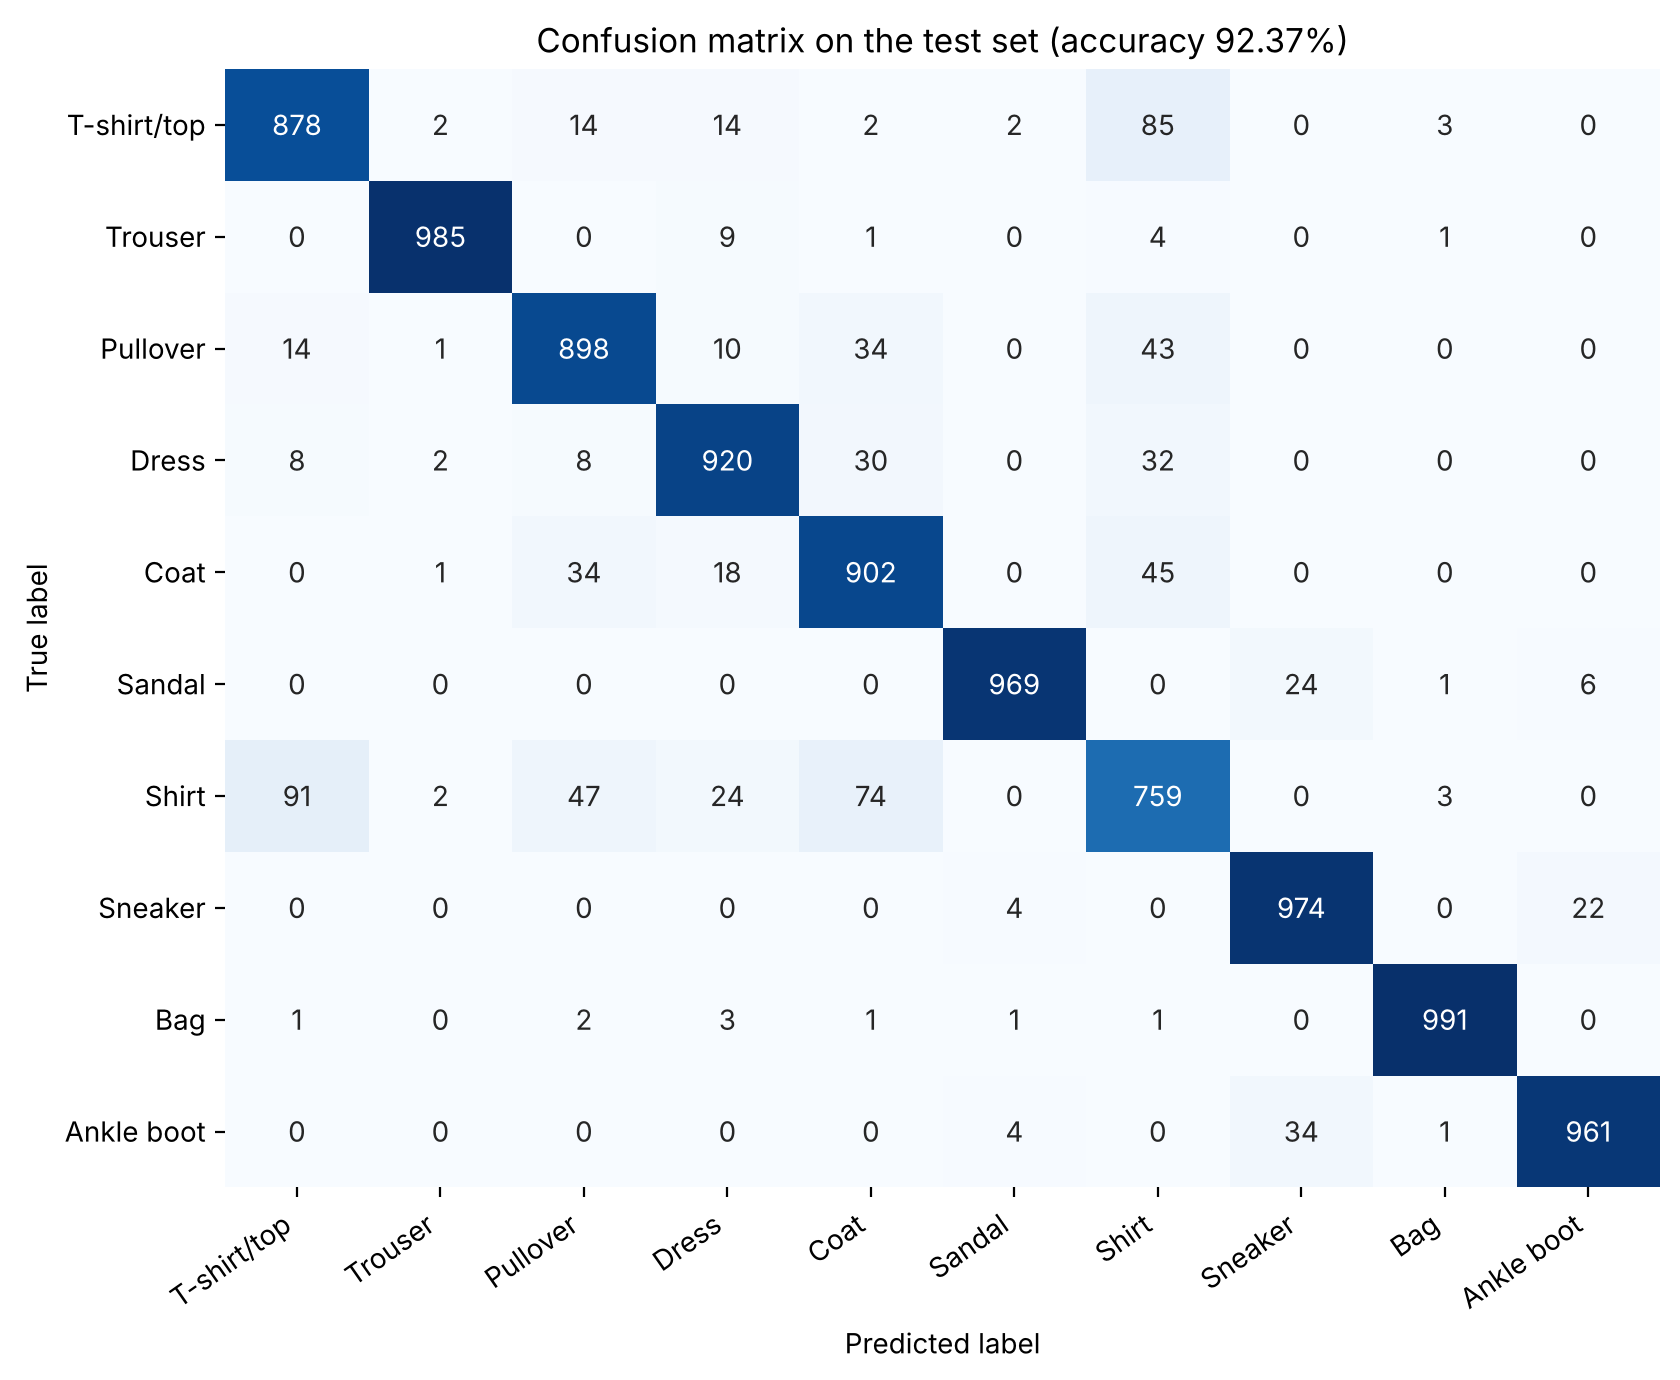

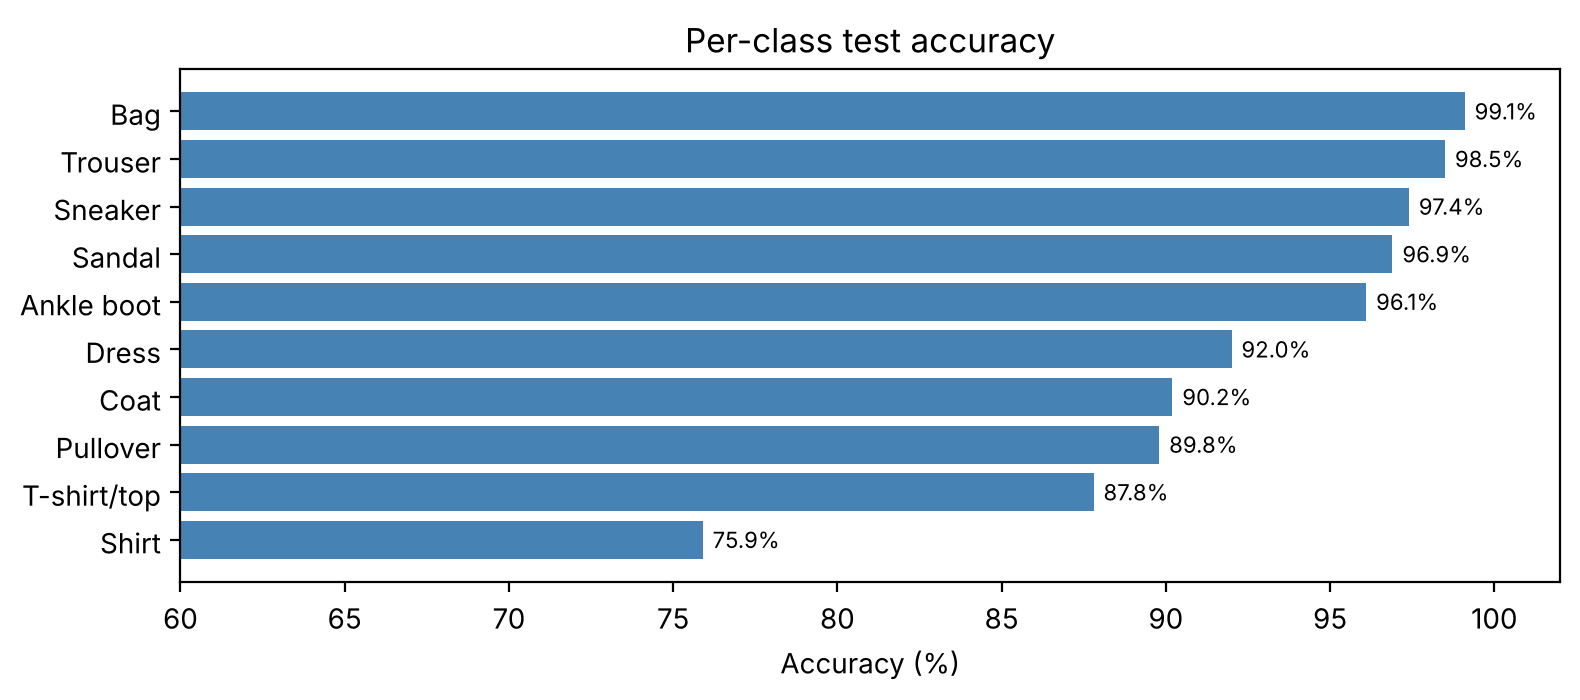

Most frequent mistakes (true -> predicted):
  Shirt        -> T-shirt/top : 91 images
  T-shirt/top  -> Shirt       : 85 images
  Shirt        -> Coat        : 74 images
  Shirt        -> Pullover    : 47 images
  Coat         -> Shirt       : 45 images


In [17]:
# ---- Confusion matrix ----
cm = confusion_matrix(test_labels, test_preds)
plt.figure(figsize=(8.5, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, cbar=False)
plt.xlabel("Predicted label"); plt.ylabel("True label")
plt.title(f"Confusion matrix on the test set (accuracy {test_acc*100:.2f}%)")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

# ---- Per-class accuracy (= recall) ----
per_class = cm.diagonal() / cm.sum(1)
order = np.argsort(per_class)
plt.figure(figsize=(8, 3.6))
plt.barh(np.array(CLASSES)[order], per_class[order] * 100, color="steelblue")
for i, v in enumerate(per_class[order] * 100):
    plt.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=8)
plt.xlim(60, 102); plt.xlabel("Accuracy (%)"); plt.title("Per-class test accuracy")
plt.tight_layout(); plt.show()

# ---- Most frequent confusions ----
off = cm.copy(); np.fill_diagonal(off, 0)
top = np.dstack(np.unravel_index(np.argsort(off.ravel())[::-1][:5], off.shape))[0]
print("Most frequent mistakes (true -> predicted):")
for t, p in top:
    print(f"  {CLASSES[t]:12s} -> {CLASSES[p]:12s}: {off[t, p]} images")

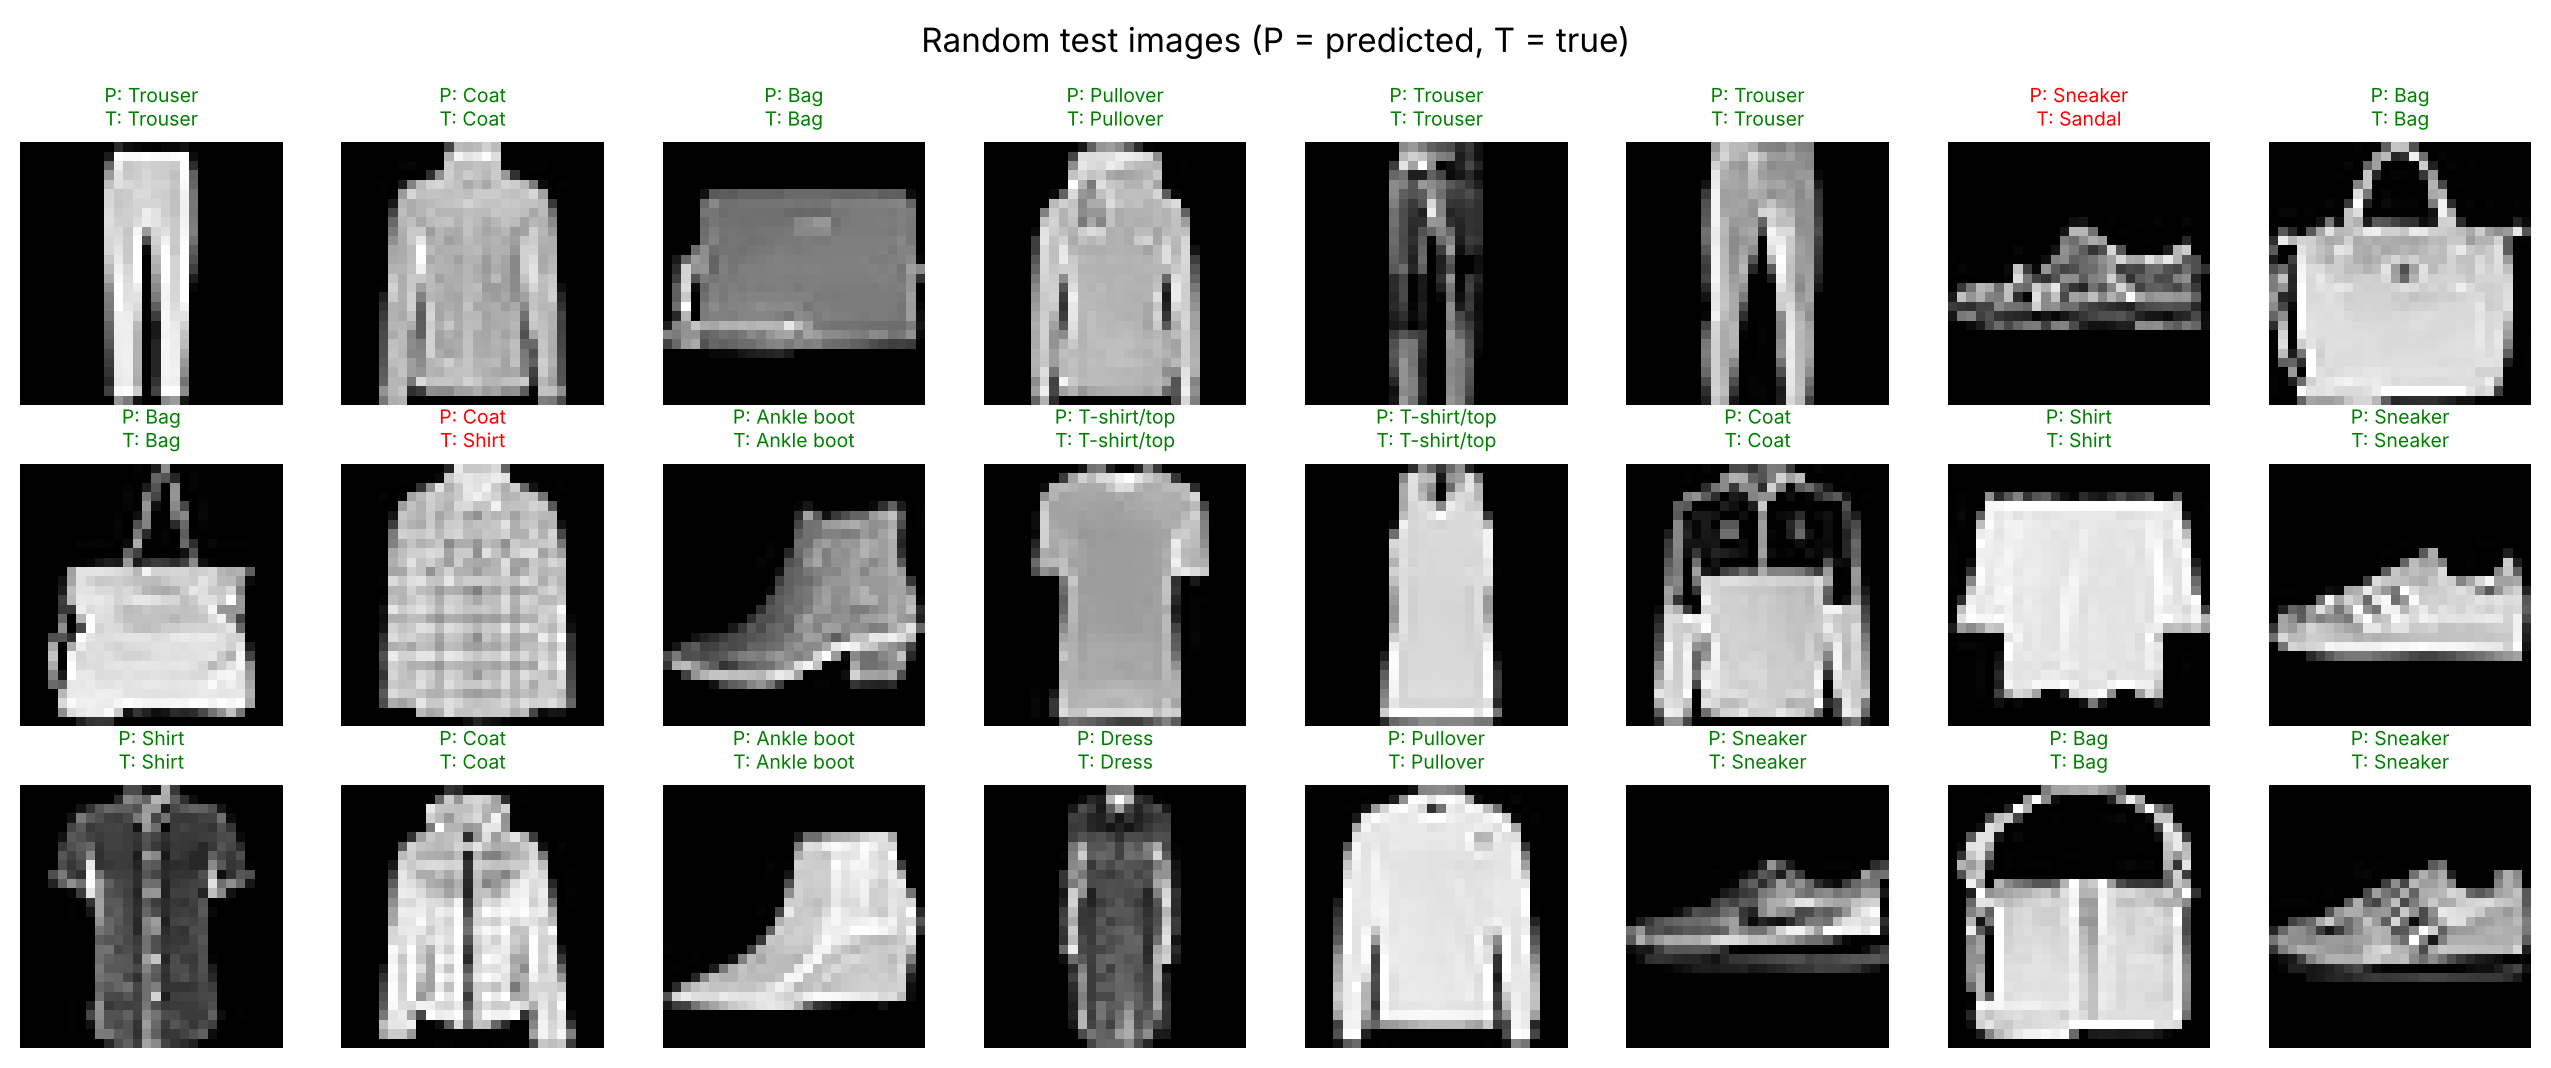

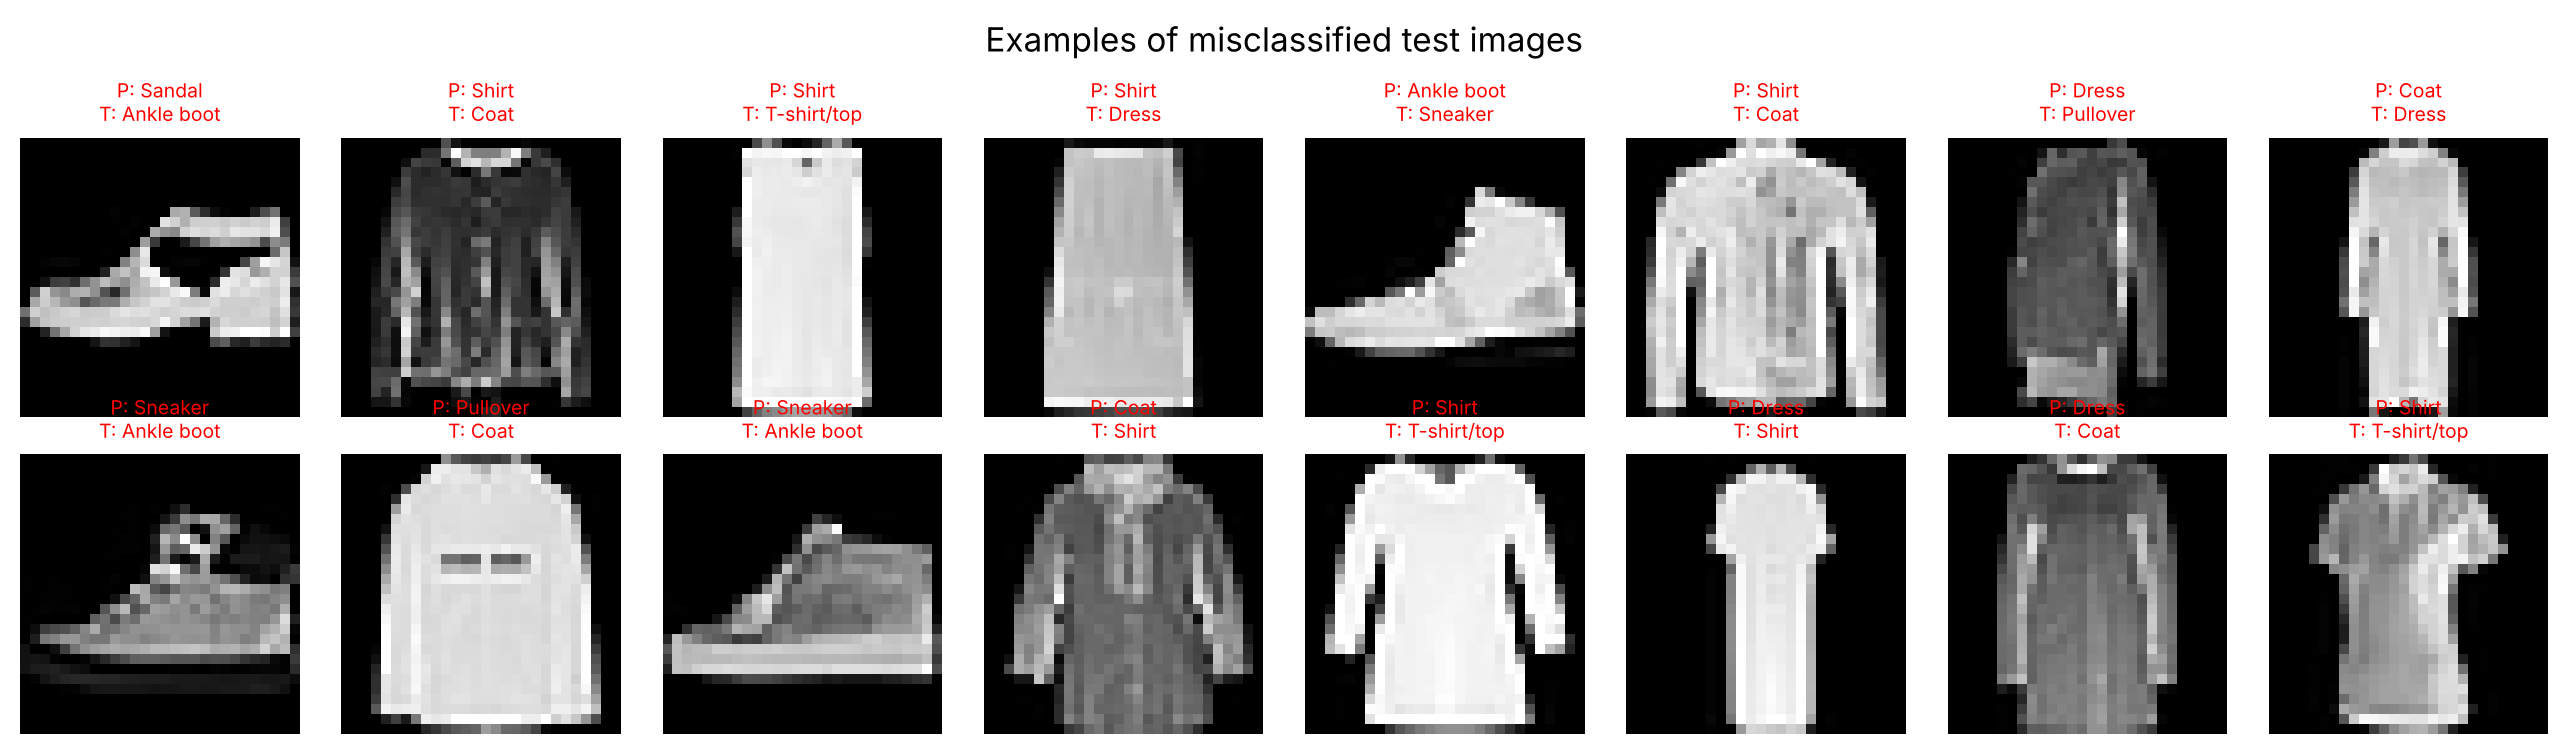

In [18]:
# ---- Example predictions: correct in green, wrong in red ----
images_shown = 0
fig, axes = plt.subplots(3, 8, figsize=(13, 5.4))
rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(test_set), 24, replace=False)
for ax, i in zip(axes.flat, sample_idx):
    ax.imshow(raw_test.data[i], cmap="gray"); ax.axis("off")
    ok = test_preds[i] == test_labels[i]
    ax.set_title(f"P: {CLASSES[test_preds[i]]}\nT: {CLASSES[test_labels[i]]}", fontsize=7,
                 color="green" if ok else "red")
plt.suptitle("Random test images (P = predicted, T = true)"); plt.tight_layout(); plt.show()

# ---- Misclassified examples ----
wrong = np.where(test_preds != test_labels)[0][:16]
fig, axes = plt.subplots(2, 8, figsize=(13, 3.8))
for ax, i in zip(axes.flat, wrong):
    ax.imshow(raw_test.data[i], cmap="gray"); ax.axis("off")
    ax.set_title(f"P: {CLASSES[test_preds[i]]}\nT: {CLASSES[test_labels[i]]}", fontsize=7, color="red")
plt.suptitle("Examples of misclassified test images"); plt.tight_layout(); plt.show()

## 7. Visualizations (Loss/Accuracy Curves)

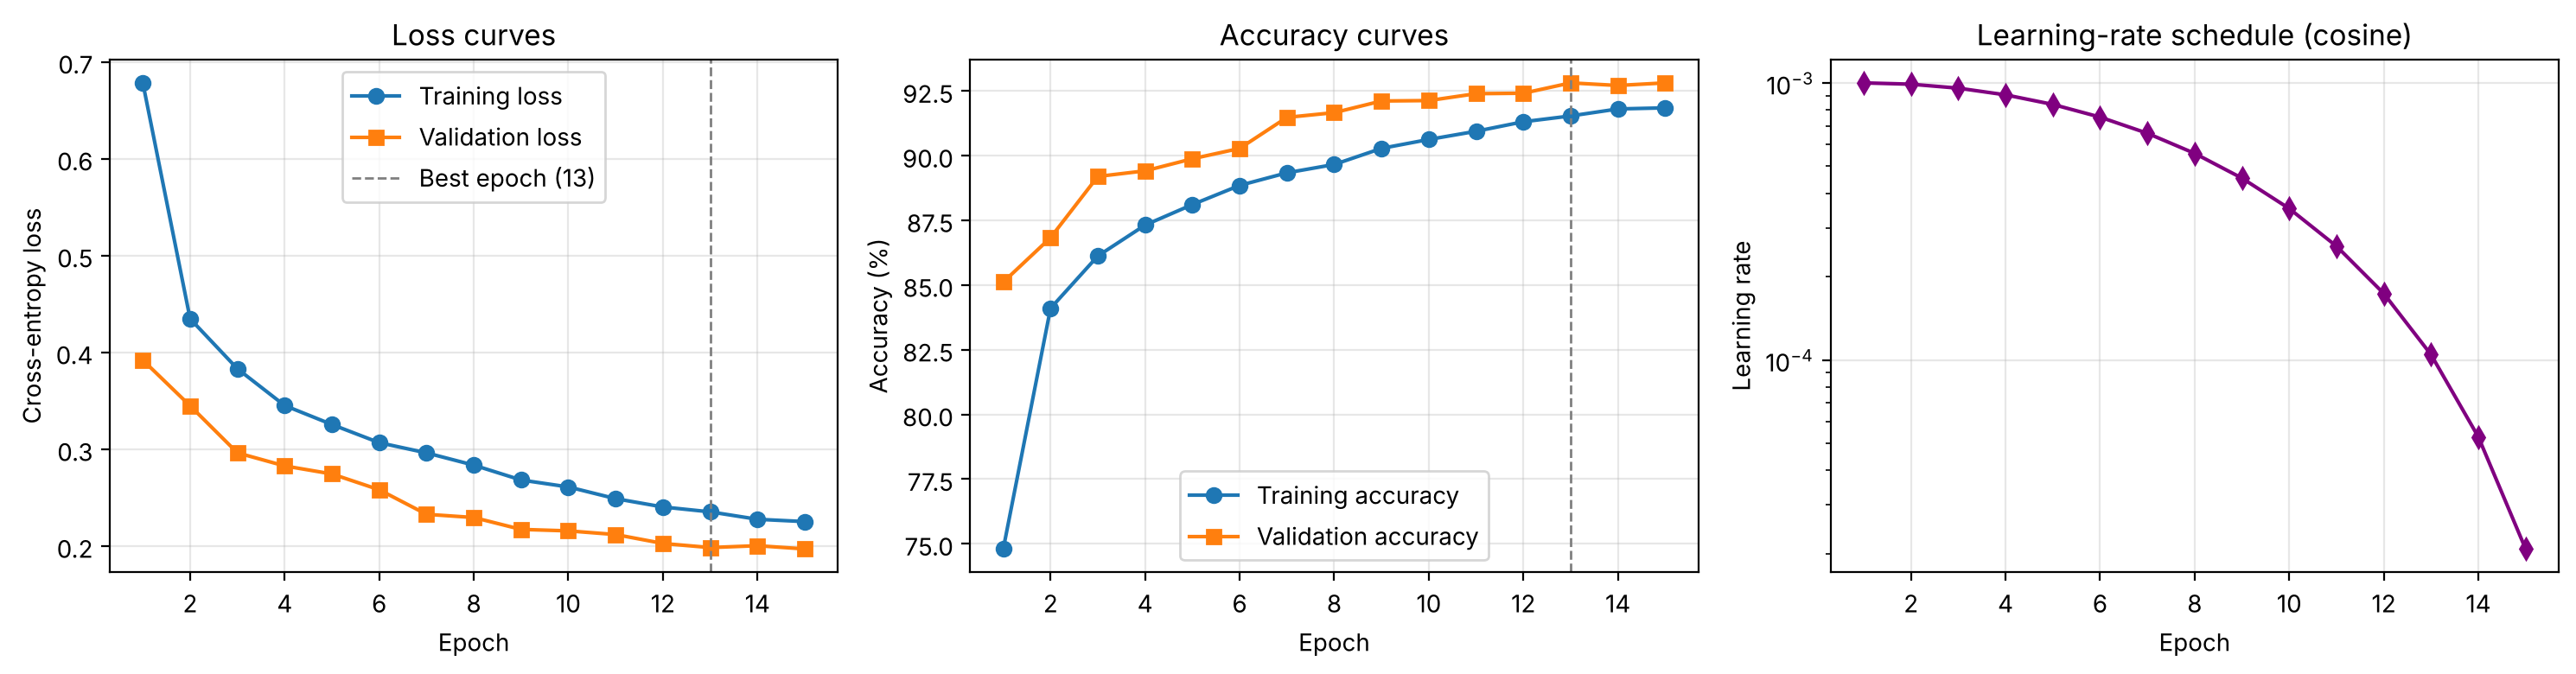

Final epoch: train acc 91.85%, val acc 92.82% (gap -0.96 pp)


In [19]:
epochs = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(epochs, history["train_loss"], "o-", label="Training loss")
axes[0].plot(epochs, history["val_loss"], "s-", label="Validation loss")
axes[0].axvline(best_epoch, color="gray", ls="--", lw=1, label=f"Best epoch ({best_epoch})")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Cross-entropy loss"); axes[0].set_title("Loss curves")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs, np.array(history["train_acc"]) * 100, "o-", label="Training accuracy")
axes[1].plot(epochs, np.array(history["val_acc"]) * 100, "s-", label="Validation accuracy")
axes[1].axvline(best_epoch, color="gray", ls="--", lw=1)
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy (%)"); axes[1].set_title("Accuracy curves")
axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(epochs, history["lr"], "d-", color="purple")
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Learning rate"); axes[2].set_title("Learning-rate schedule (cosine)")
axes[2].set_yscale("log"); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

gap = (history["train_acc"][-1] - history["val_acc"][-1]) * 100
print(f"Final epoch: train acc {history['train_acc'][-1]*100:.2f}%, val acc {history['val_acc'][-1]*100:.2f}% "
      f"(gap {gap:+.2f} pp)")

### Explanation of the curves

* **Loss curves.** Both losses fall steadily: training loss drops from 0.678 to 0.225 and validation loss from 0.392 to 0.197.
  Validation loss never turns upward, which is the usual sign of over-fitting, so the model **does not over-fit**.
* **Accuracy curves.** Most of the gain comes in the first three epochs (validation 85.1 % → 89.2 %).
  Improvement then slows and levels off at about 92.7–92.8 % in epochs 13–15. The best validation accuracy, **92.82 % at epoch 13**, is the checkpoint that was saved.
* **Why validation is higher than training.** Validation accuracy (92.82 %) is slightly *above* training accuracy (91.85 %), and validation loss is *below*
  training loss. This is expected: training metrics are measured with dropout switched on and on augmented (shifted/flipped) images, while validation uses the full network on clean images.
  The small negative gap (−0.96 percentage points) shows the regularisation is working. If anything, the model is slightly under-fitting.
* **Learning-rate schedule.** The cosine schedule lowers the learning rate from 1e-3 to about 2e-5. The large early steps give the fast initial gains,
  and the small late steps give the smooth final improvements in epochs 10–15.

## 8. Analysis & Discussion of Results

### Overall performance

| Metric (10,000 test images) | Value |
|---|---|
| Test accuracy | **92.37 %** |
| Macro precision / recall / F1 | 92.37 % / 92.37 % / 92.36 % |
| Test loss (cross-entropy) | 0.209 |
| Best validation accuracy (epoch 13) | 92.82 % |
| Trainable parameters / weight-file size | 436,906 / 1.76 MB |
| Training time | 19.9 min on a 2-core CPU (15 epochs) |

Test accuracy (92.37 %) is within 0.5 percentage points of validation accuracy (92.82 %). This means the validation set gave a reliable estimate and the
model **generalises well to unseen images**.

### Per-class behaviour
* **Easiest classes:** Bag (99.1 % recall), Trouser (98.5 %), Sneaker (97.4 %), Sandal (96.9 %) and Ankle boot (96.1 %). Each has a distinctive shape
  that no other class shares.
* **Hardest class:** **Shirt** (75.9 % recall, F1 = 0.771), followed by T-shirt/top (87.8 %), Pullover (89.8 %) and Coat (90.2 %).
* **Main confusions** (from the confusion matrix): Shirt → T-shirt/top (91), T-shirt/top → Shirt (85), Shirt → Coat (74), Shirt → Pullover (47) and Coat → Shirt (45).
  All five are between **upper-body garments with nearly the same silhouette**. At 28 × 28 pixels the features that separate them (collar, buttons, sleeve length,
  fabric texture) take up only a few pixels, and some images are ambiguous even to people: the crowd-sourced human baseline in the dataset's benchmark table is 83.5 %.
* Footwear classes (Sandal, Sneaker, Ankle boot) are confused with each other only occasionally, and almost never with clothing.

### Effect of the design choices
* **BatchNorm + Adam** gave fast, stable convergence: 85 % validation accuracy after a single epoch.
* **Data augmentation + dropout** prevented over-fitting. Training and validation curves stay together for all 15 epochs.
* **Cosine learning-rate decay** produced the steady improvement in the last epochs without manual tuning.
* **Choosing the best validation epoch** means the saved weights are the best-generalising ones, not simply the last ones.

### Limitations
* Training was limited to 15 epochs on a CPU. The curves were still rising slowly, so a longer schedule would probably add a little accuracy.
* The results come from a single run with seed 42; no systematic hyperparameter search was carried out.

## 9. Conclusions & Future Work

### Conclusions
* A custom 5-convolution-layer CNN with BatchNorm, max-pooling and dropout (0.44 M parameters) was designed and trained from scratch on Fashion-MNIST.
* With Adam (lr = 1e-3, weight decay = 1e-4), cross-entropy loss, a cosine learning-rate schedule and light augmentation, it reached
  **92.82 % validation accuracy** and **92.37 % test accuracy** (macro F1 = 0.924) in 15 epochs, with no sign of over-fitting.
* Most of the remaining errors are between visually similar upper-body garments, Shirt above all. These are a known limitation of low-resolution grayscale images.
* The trained weights were saved (`saved_models/fashion_cnn_best.pth`, 1.76 MB), then reloaded and verified to give the same validation accuracy.

### Future work
1. **Train longer** (25–40 epochs) with the same cosine schedule, since validation accuracy was still slowly improving.
2. **Stronger regularisation and augmentation**, e.g. Random Erasing / Cutout and label smoothing, to help separate Shirt from T-shirt, Coat and Pullover.
3. **Architecture changes:** wider layers, residual (ResNet-style) connections, or global average pooling in place of the large fully connected layer.
4. **Hyperparameter search** (learning rate, batch size, dropout) on the validation set, and repeating runs with several seeds to report mean ± std.
5. **Interpretability:** Grad-CAM heat-maps to see which garment regions the model uses when it confuses Shirt with T-shirt.
6. **Transfer learning** with a pretrained network (e.g. ResNet-18 with images resized to 3 × 224 × 224) as a comparison baseline.

### Repository contents
```
CNN_StudentID.ipynb                 # this notebook, with all outputs
saved_models/fashion_cnn_best.pth   # trained weights (1.76 MB, below the 20 MB limit)
saved_models/history.json           # per-epoch loss / accuracy / learning rate
saved_models/test_metrics.json      # final test-set metrics
```